In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})


In [2]:
keyword = 'stock'
gendata = np.load(f'../Analysis/Dataset/{keyword}/timeGAN/generated_data_24.npy')
oridata = np.load(f'../Analysis/Dataset/{keyword}/timeGAN/ori_data_24.npy')

In [18]:
import os
import re
import random
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


def _safe_filename(s: str) -> str:
    """替换不适合文件名的字符，保留空格。"""
    return re.sub(r'[\\/:*?"<>|]', '-', str(s)).strip()


def _save_fig(
    fig,
    analysis,
    title_suffix,
    dataset_name,
    save_root="Plot",
    dpi=300,
    gen_label=None,
):
    """按指定规则保存图片到 save_root/dataset_name 下。"""
    if dataset_name is None or title_suffix is None:
        return

    kind = {"pca": "PCA", "tsne": "t-SNE", "kernel": "CDF"}[analysis]
    ds = _safe_filename(dataset_name)
    suf = _safe_filename(title_suffix)
    glb = _safe_filename(gen_label) if gen_label else None

    out_dir = os.path.join(save_root, ds)
    os.makedirs(out_dir, exist_ok=True)

    fname = f"{suf} {kind}" + (f" {glb}" if glb else "") + ".png"
    out_path = os.path.join(out_dir, fname)

    fig.savefig(out_path, dpi=dpi, bbox_inches="tight", pad_inches=0.1)


def visualization(
    ori_data,
    generated_data,
    analysis,
    compare=1000,
    ori_label="Original",
    gen_label="Synthetic",
    title_suffix="Overall Generation",
    dataset_name=None,
    save_root="Plot",
    save_dpi=300,
    random_seed=42,
):
    """Using PCA or tSNE or Kernel Density for visualization."""
    if random_seed is not None:
        np.random.seed(random_seed)
        random.seed(random_seed)
    # 采样（加速）
    anal_sample_no = min([compare, ori_data.shape[0]])
    idx = np.random.permutation(ori_data.shape[0])[:anal_sample_no]

    ori_data = ori_data[idx]
    generated_data = generated_data[idx]

    # 形状：(N, seq_len, dim)
    no, seq_len, dim = ori_data.shape

    # 准备样本（对特征维求均值 -> (N, seq_len)）
    for i in range(anal_sample_no):
        if i == 0:
            prep_data = np.reshape(np.mean(ori_data[0, :, :], 1), [1, seq_len])
            prep_data_hat = np.reshape(np.mean(generated_data[0, :, :], 1), [1, seq_len])
        else:
            prep_data = np.concatenate(
                (prep_data, np.reshape(np.mean(ori_data[i, :, :], 1), [1, seq_len]))
            )
            prep_data_hat = np.concatenate(
                (prep_data_hat, np.reshape(np.mean(generated_data[i, :, :], 1), [1, seq_len]))
            )

    colors = ["red"] * anal_sample_no + ["blue"] * anal_sample_no

    if analysis == "pca":
        # PCA
        pca = PCA(n_components=2)
        pca.fit(prep_data)
        pca_results = pca.transform(prep_data)
        pca_hat_results = pca.transform(prep_data_hat)

        # 绘图
        f, ax = plt.subplots(1)
        plt.scatter(
            pca_results[:, 0],
            pca_results[:, 1],
            c=colors[:anal_sample_no],
            alpha=0.2,
            label=ori_label,
        )
        plt.scatter(
            pca_hat_results[:, 0],
            pca_hat_results[:, 1],
            c=colors[anal_sample_no:],
            alpha=0.2,
            label=gen_label,
        )

        ax.legend(loc="upper right", bbox_to_anchor=(1.05, 1.05), fontsize=20)
        #plt.ylim(-0.3,0.4)
        #plt.title(f"PCA {title_suffix}", fontsize=25)
        ax.tick_params(axis="both", which="major", labelsize=25)

        _save_fig(
            f,
            "pca",
            title_suffix,
            dataset_name,
            save_root,
            dpi=save_dpi,
            gen_label=gen_label,
        )
        plt.show()

    elif analysis == "tsne":
        # t-SNE
        prep_data_final = np.concatenate((prep_data, prep_data_hat), axis=0)
        tsne = TSNE(
            n_components=2,
            verbose=1,
            perplexity=40,
            max_iter=300,
            random_state=random_seed,
        )
        tsne_results = tsne.fit_transform(prep_data_final)

        # 绘图
        f, ax = plt.subplots(1, figsize=(6, 4))
        plt.scatter(
            tsne_results[:anal_sample_no, 0],
            tsne_results[:anal_sample_no, 1],
            c=colors[:anal_sample_no],
            alpha=0.2,
            label=ori_label,
        )
        plt.scatter(
            tsne_results[anal_sample_no:, 0],
            tsne_results[anal_sample_no:, 1],
            c=colors[anal_sample_no:],
            alpha=0.2,
            label=gen_label,
        )

        ax.legend(loc="lower left", bbox_to_anchor=(-0.1, -0.11), fontsize=30)
        #plt.ylim(-25,25)
        #plt.title(f"{title_suffix}", fontsize=25)
        ax.tick_params(axis="both", which="major", labelsize=30)

        plt.tight_layout()
        plt.savefig(f"../Analysis/Plot/distribution.png", dpi=300)
        plt.show()

    elif analysis == "kernel":
        # KDE（你称为 CDF 图标题）
        f, ax = plt.subplots(1)
        sns.kdeplot(prep_data.flatten(), linewidth=3, label=ori_label, color="red")
        sns.kdeplot(
            prep_data_hat.flatten(),
            linewidth=3,
            linestyle="--",
            label=gen_label,
            color="blue",
        )

        ax.legend(loc="upper right", bbox_to_anchor=(1.05, 1.05), fontsize=20)
        #plt.ylim(0,5)
        plt.title(f"CDF {title_suffix}", fontsize=25)
        plt.xlabel("Data Value", fontsize=30)
        plt.ylabel("Density", fontsize=30)
        ax.tick_params(axis="both", which="major", labelsize=25)


        plt.show()
        plt.close()


[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 2000 samples in 0.000s...
[t-SNE] Computed neighbors for 2000 samples in 0.049s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2000
[t-SNE] Computed conditional probabilities for sample 2000 / 2000
[t-SNE] Mean sigma: 0.028909
[t-SNE] KL divergence after 250 iterations with early exaggeration: 50.407738
[t-SNE] KL divergence after 300 iterations: 0.842466


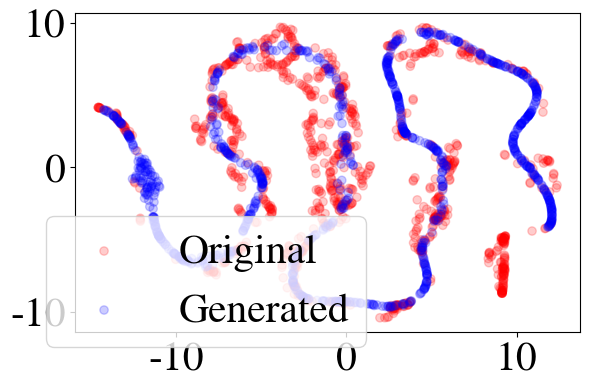

In [19]:
visualization(oridata,gendata,'tsne',ori_label="Original", gen_label="Generated",title_suffix="t-SNE Distribution",dataset_name= 'stock',random_seed = 42)